In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df= pd.read_csv(r"C:\Users\singh\OneDrive\Desktop\Real-Estate-Price-Prediction\data\processed\house_prices_cleaned.csv")
df.head()

,area_type,availability,location,size,total_sqft,bath,balcony,price,bhk,total_sqft_num
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056,2.0,1.0,39.07,2.0,1056.0
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600,5.0,3.0,120.00,4.0,2600.0
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440,2.0,3.0,62.00,3.0,1440.0
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521,3.0,1.0,95.00,3.0,1521.0
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200,2.0,1.0,51.00,2.0,1200.0


#EDA 1

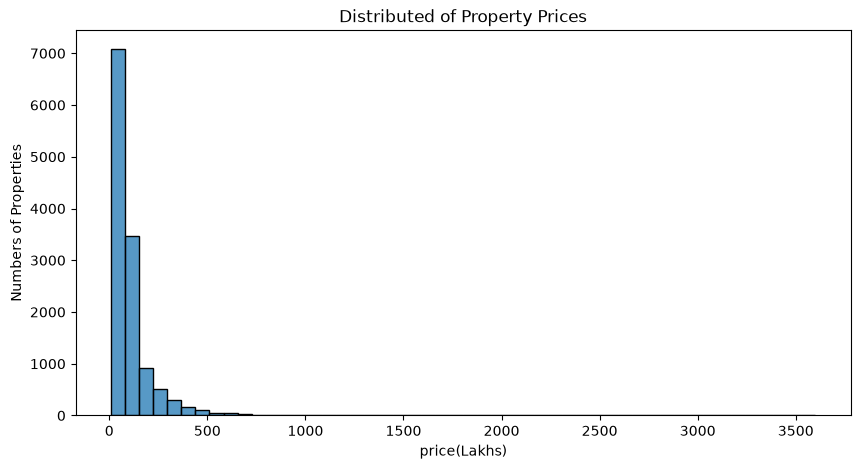

In [4]:
plt.figure(figsize=(10,5))
sns.histplot(df["price"],bins=50)

plt.title("Distributed of Property Prices")
plt.xlabel("price(Lakhs)")
plt.ylabel("Numbers of Properties")
plt.show()

#EDA 2

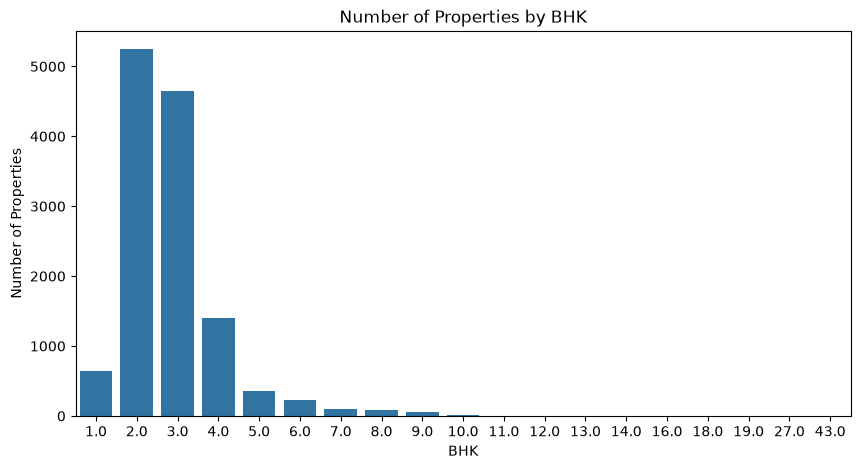

In [8]:
plt.figure(figsize=(10,5))
sns.countplot(data=df,x="bhk")
plt.title("Number of Properties by BHK")
plt.xlabel("BHK")
plt.ylabel("Number of Properties")
plt.show()


#EDA 3

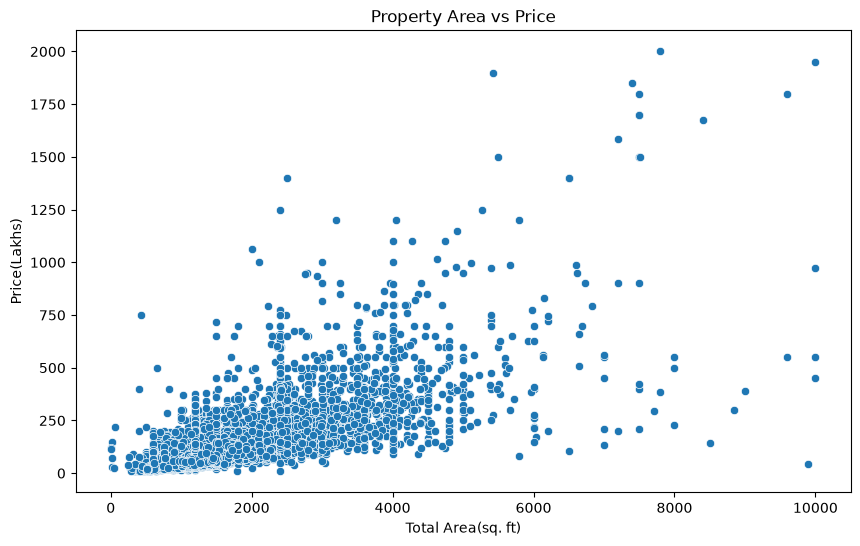

In [23]:
df_plot = df[
    (df["total_sqft_num"] <= 10000) &
    (df["price"] <= 2000)
]


plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df_plot,
    x="total_sqft_num",
    y="price"
)

plt.title("Property Area vs Price")
plt.xlabel("Total Area(sq. ft)")
plt.ylabel("Price(Lakhs)")
plt.show()

#EDA 4 BHK VS PRICE

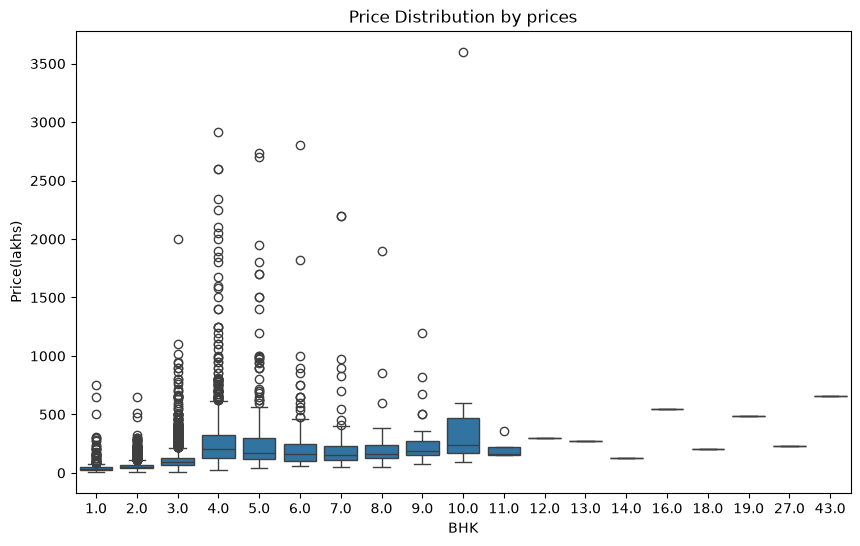

In [27]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df,
    x="bhk",
    y="price"

)
plt.title("Price Distribution by prices")
plt.xlabel("BHK")
plt.ylabel("Price(lakhs)")
plt.show()

#EDA 5

In [ ]:
df["price_per_sqft"] = (
    df["price"] * 100000 / df["total_sqft_num"]
)


In [35]:
df[["price", "total_sqft_num", "price_per_sqft"]].head()

,price,total_sqft_num,price_per_sqft
0,39.07,1056.0,3699.810606
1,120.00,2600.0,4615.384615
2,62.00,1440.0,4305.555556
3,95.00,1521.0,6245.890861
4,51.00,1200.0,4250.000000


#EDA 6 LOCATION

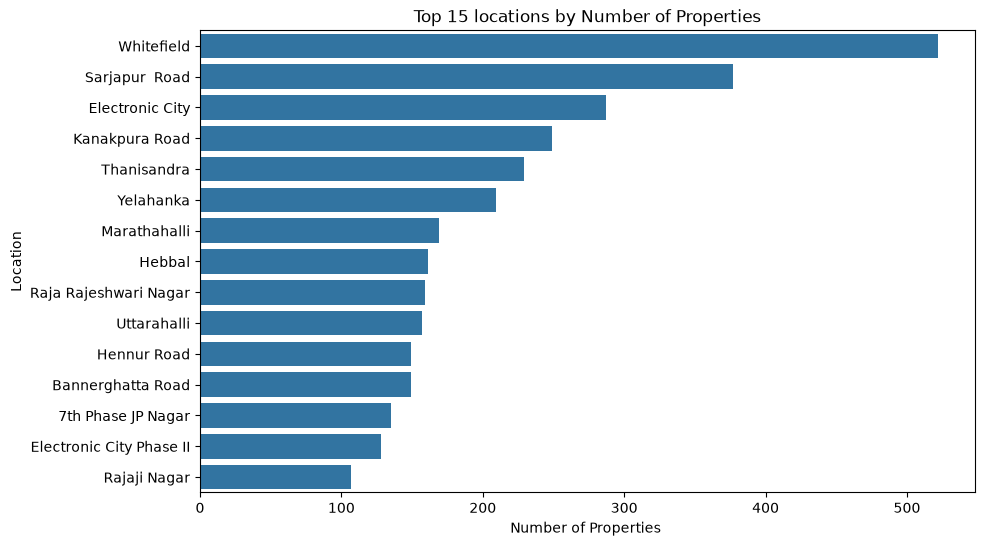

In [36]:
location_counts = df["location"].value_counts().head(15)
plt.figure(figsize=(10,6))

sns.barplot(
    x=location_counts.values,
    y=location_counts.index
)

plt.title("Top 15 locations by Number of Properties")
plt.xlabel("Number of Properties ")
plt.ylabel("Location")

plt.show()

#EDA 7 AVG PRICE BY LOCATION

In [38]:
location_price=(
    df.groupby("location")["price"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

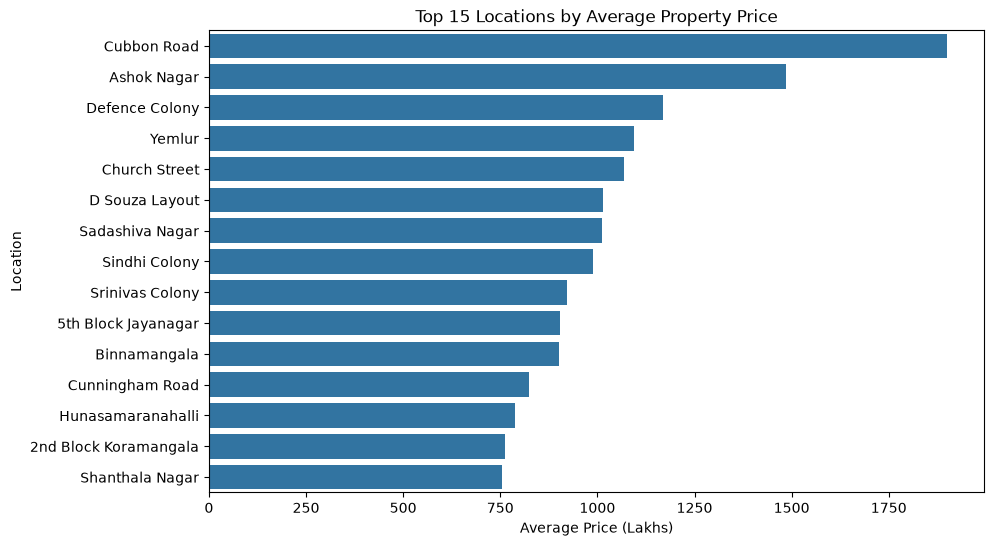

In [40]:
plt.figure(figsize=(10,6))
sns.barplot(
    x=location_price.values,
    y=location_price.index
)
plt.title("Top 15 Locations by Average Property Price")
plt.xlabel("Average Price (Lakhs)")
plt.ylabel("Location")

plt.show()


#Feature Engineering


In [42]:
df["sqft_per_bhk"] = df["total_sqft_num"] / df["bhk"]

In [44]:
df[["bhk","total_sqft_num","sqft_per_bhk"]].head(10)

,bhk,total_sqft_num,sqft_per_bhk
0,2.0,1056.0,528.000000
1,4.0,2600.0,650.000000
2,3.0,1440.0,480.000000
3,3.0,1521.0,507.000000
4,2.0,1200.0,600.000000
5,2.0,1170.0,585.000000
6,4.0,2732.0,683.000000
7,4.0,3300.0,825.000000
8,3.0,1310.0,436.666667
9,6.0,1020.0,170.000000


In [48]:
df[df["sqft_per_bhk"] <300][
    ["location","bhk","total_sqft_num","sqft_per_bhk","price"]
].head(20)

,location,bhk,total_sqft_num,sqft_per_bhk,price
9,Gandhi Bazar,6.0,1020.0,170.000000,370.0
45,HSR Layout,8.0,600.0,75.000000,200.0
58,Murugeshpalya,6.0,1407.0,234.500000,150.0
68,Devarachikkanahalli,8.0,1350.0,168.750000,85.0
70,Double Road,3.0,500.0,166.666667,100.0
78,Kaval Byrasandra,2.0,460.0,230.000000,22.0
89,Rajaji Nagar,6.0,710.0,118.333333,160.0
119,Hennur Road,2.0,276.0,138.000000,23.0
129,Vishwapriya Layout,7.0,950.0,135.714286,115.0
149,Dinnur,6.0,1034.0,172.333333,185.0


In [51]:
suspicious= df[df["sqft_per_bhk"]<300]
print("suspicious",len(suspicious))

suspicious 738


In [52]:
df["sqft_per_bhk"].describe()

count     12774.000000
mean        708.301727
std        6697.764337
min           0.250000
25%         473.333333
50%         552.500000
75%         627.000000
max      653400.000000
Name: sqft_per_bhk, dtype: float64

In [53]:
df[
    ["location", "bhk", "total_sqft_num", "sqft_per_bhk", "price"]
].sort_values("sqft_per_bhk").head(20)

,location,bhk,total_sqft_num,sqft_per_bhk,price
4027,Sarjapur Road,4.0,1.0000,0.250000,120.0
4888,Srirampuram,7.0,5.0000,0.714286,115.0
349,Suragajakkanahalli,3.0,11.0000,3.666667,74.0
1118,Grihalakshmi Layout,5.0,24.0000,4.800000,150.0
1017,Weavers Colony,1.0,15.0000,15.000000,30.0
11137,Whitefield,4.0,60.0000,15.000000,218.0
5849,Mysore Road,1.0,45.0000,45.000000,23.0
11782,Gowdanapalya,5.0,258.3336,51.666720,75.0
4612,Munnekollal,43.0,2400.0000,55.813953,660.0
6654,Sector 2 HSR Layout,9.0,600.0000,66.666667,90.0


In [54]:
df[
    ["location", "bhk", "total_sqft_num", "sqft_per_bhk", "price"]
].sort_values("sqft_per_bhk", ascending=False).head(20)

,location,bhk,total_sqft_num,sqft_per_bhk,price
1083,Narasapura,2.0,1306800.00,653400.000000,29.5
1016,Marathi Layout,1.0,231303.60,231303.600000,110.0
7418,Bommenahalli,3.0,653400.00,217800.000000,217.0
646,Arekere,9.0,1123031.25,124781.250000,265.0
11188,arudi,3.0,261360.00,87120.000000,80.0
7157,Kanakpura Road,1.0,87120.00,87120.000000,125.0
6834,Thyagaraja Nagar,8.0,653400.00,81675.000000,290.0
7534,Kanakpura Road,1.0,54885.60,54885.600000,125.0
6195,Harohalli,2.0,91040.40,45520.200000,200.0
10914,Arishinakunte,1.0,41382.00,41382.000000,170.0


In [56]:
df_model= df[df["sqft_per_bhk"]>=300].copy()

In [60]:
print("original rows",len(df))
print("rows after filtering",len(df_model))
print("rows removed",len(df)-len(df_model))

original rows 12774
rows after filtering 12036
rows removed 738


In [66]:
large_area= df_model[df_model["total_sqft_num"] > 10000]
print("Properties above 10000 sq. ft =",len(large_area))
large_area["area_type"].value_counts()

Properties above 10000 sq. ft = 41


area_type
Plot  Area              27
Super built-up  Area     9
Built-up  Area           5
Name: count, dtype: int64

In [67]:
large_area[
    ["area_type", "location", "bhk", "total_sqft_num", "price"]
].sort_values("total_sqft_num", ascending=False).head(20)

,area_type,location,bhk,total_sqft_num,price
1083,Plot Area,Narasapura,2.0,1306800.000,29.5
646,Built-up Area,Arekere,9.0,1123031.250,265.0
6834,Plot Area,Thyagaraja Nagar,8.0,653400.000,290.0
7418,Plot Area,Bommenahalli,3.0,653400.000,217.0
11188,Plot Area,arudi,3.0,261360.000,80.0
1016,Plot Area,Marathi Layout,1.0,231303.600,110.0
6195,Plot Area,Harohalli,2.0,91040.400,200.0
7157,Plot Area,Kanakpura Road,1.0,87120.000,125.0
7534,Plot Area,Kanakpura Road,1.0,54885.600,125.0
10138,Plot Area,2 Bedroom Furnished Farm House in Kolar Road,2.0,54450.000,200.0


In [68]:
large_area[
    ["area_type", "location", "size", "total_sqft",
     "total_sqft_num", "bhk", "price"]
].sort_values(
    "total_sqft_num",
    ascending=False
).head(20)

,area_type,location,size,total_sqft,total_sqft_num,bhk,price
1083,Plot Area,Narasapura,2 Bedroom,30Acres,1306800.000,2.0,29.5
646,Built-up Area,Arekere,9 Bedroom,4125Perch,1123031.250,9.0,265.0
6834,Plot Area,Thyagaraja Nagar,8 Bedroom,1500Cents,653400.000,8.0,290.0
7418,Plot Area,Bommenahalli,3 Bedroom,15Acres,653400.000,3.0,217.0
11188,Plot Area,arudi,3 Bedroom,6Acres,261360.000,3.0,80.0
1016,Plot Area,Marathi Layout,1 Bedroom,5.31Acres,231303.600,1.0,110.0
6195,Plot Area,Harohalli,2 Bedroom,2.09Acres,91040.400,2.0,200.0
7157,Plot Area,Kanakpura Road,1 Bedroom,2Acres,87120.000,1.0,125.0
7534,Plot Area,Kanakpura Road,1 Bedroom,1.26Acres,54885.600,1.0,125.0
10138,Plot Area,2 Bedroom Furnished Farm House in Kolar Road,2 Bedroom,1.25Acres,54450.000,2.0,200.0


In [80]:
df_model= df_model[
    df_model["area_type"] != "Plot  Area"
].copy()


In [81]:
print("Rows after removing Plot Area:", len(df_model))
df_model["area_type"].value_counts()

Rows after removing Plot Area: 10680


area_type
Super built-up  Area    8268
Built-up  Area          2329
Carpet  Area              83
Name: count, dtype: int64

In [83]:
large_non_plot = df_model[df_model["total_sqft_num"] > 10000]

print("Remaining properties above 10,000 sq.ft:",
      len(large_non_plot))

Remaining properties above 10,000 sq.ft: 14


In [84]:
large_non_plot[
    ["area_type", "location", "size",
     "total_sqft", "total_sqft_num", "bhk", "price"]
].sort_values(
    "total_sqft_num",
    ascending=False
).head(20)

,area_type,location,size,total_sqft,total_sqft_num,bhk,price
646,Built-up Area,Arekere,9 Bedroom,4125Perch,1123031.250,9.0,265.0
5297,Super built-up Area,Doddabommasandra,9 BHK,42000,42000.000,9.0,175.0
5369,Super built-up Area,Ulsoor,4 BHK,36000,36000.000,4.0,450.0
672,Built-up Area,Yelahanka,3 BHK,35000,35000.000,3.0,130.0
3186,Built-up Area,Dodda Banaswadi,5 Bedroom,3040Sq. Meter,32722.256,5.0,140.0
9216,Built-up Area,Bommenahalli,3 Bedroom,2940Sq. Yards,26460.000,3.0,232.0
11987,Super built-up Area,Nagashetty Halli,4 BHK,16335,16335.000,4.0,149.0
3058,Super built-up Area,Jp nagar 8th Phase .,10 BHK,12000,12000.000,10.0,525.0
408,Super built-up Area,Rajaji Nagar,7 BHK,12000,12000.000,7.0,2200.0
603,Super built-up Area,Malleshwaram,7 BHK,12000,12000.000,7.0,2200.0


In [85]:
large_non_plot[
    ["location", "bhk", "total_sqft_num", "price", "price_per_sqft"]
].sort_values(
    "total_sqft_num",
    ascending=False
)

,location,bhk,total_sqft_num,price,price_per_sqft
646,Arekere,9.0,1123031.250,265.0,23.596850
5297,Doddabommasandra,9.0,42000.000,175.0,416.666667
5369,Ulsoor,4.0,36000.000,450.0,1250.000000
672,Yelahanka,3.0,35000.000,130.0,371.428571
3186,Dodda Banaswadi,5.0,32722.256,140.0,427.843361
9216,Bommenahalli,3.0,26460.000,232.0,876.795163
11987,Nagashetty Halli,4.0,16335.000,149.0,912.151821
3058,Jp nagar 8th Phase .,10.0,12000.000,525.0,4375.000000
408,Rajaji Nagar,7.0,12000.000,2200.0,18333.333333
603,Malleshwaram,7.0,12000.000,2200.0,18333.333333


In [97]:
df_model = df[
    df["sqft_per_bhk"] >= 300
].copy()

df_model["area_type"] = df_model["area_type"].str.strip()

df_model = df_model[
    df_model["area_type"] != "Plot Area"
].copy()

df_model = df_model[
    df_model["total_sqft_num"] <= 20000
].copy()

In [98]:
df_model = df_model[
    df_model["total_sqft_num"] <= 20000
].copy()

In [99]:
print("Final modeling rows:", len(df_model))
print("Rows removed:", 12036 - len(df_model))

Final modeling rows: 12015
Rows removed: 21


In [100]:
df_model["area_type"].value_counts()

area_type
Super built-up  Area    8266
Built-up  Area          2325
Plot  Area              1341
Carpet  Area              83
Name: count, dtype: int64

In [101]:
df_model= df_model[
    df_model["area_type"] != "Plot  Area"
].copy()

In [102]:
df_model["area_type"].value_counts()

area_type
Super built-up  Area    8266
Built-up  Area          2325
Carpet  Area              83
Name: count, dtype: int64

In [103]:
print("Rows:", len(df_model))
print("Largest area:", df_model["total_sqft_num"].max())

Rows: 10674
Largest area: 16335.0
